## Database Schema Updates  creating new tables

In [12]:
def setup_enhanced_tables(conn):
    """Setup additional analysis tables"""
    create_queries = [
        """
        CREATE TABLE IF NOT EXISTS citation_network (
            source_case_id TEXT,
            target_case_id TEXT,
            citation_weight REAL,
            PRIMARY KEY (source_case_id, target_case_id)
        );
        """,
        """
        CREATE TABLE IF NOT EXISTS quality_metrics (
            metric_id INTEGER PRIMARY KEY,
            check_date TIMESTAMP,
            completeness_score REAL,
            consistency_score REAL
        );
        """
    ]
    
    for query in create_queries:
        conn.execute(query)
    conn.commit()

In [13]:
# advanced_analysis.ipynb

import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
import logging
import time

# Δημιουργία του logger για καταγραφή της προόδου
logger = logging.getLogger('advanced_analysis')
logger.setLevel(logging.INFO)
fh = logging.FileHandler('logs/advanced_analysis.log', encoding='utf-8')
fh.setFormatter(logging.Formatter('%(asctime)s - %(name)s - %(levelname)s - %(message)s'))
logger.addHandler(fh)

class AdvancedTextAnalyzer:
    def __init__(self, db_connection):
        self.db = db_connection
        self.analysis_start_time = None
        
    def analyze_language_patterns(self, text_data):
        """Προχωρημένη ανάλυση γλωσσικών μοτίβων στα νομικά κείμενα"""
        try:
            # Εξαγωγή σύνθετων χαρακτηριστικών
            vectorizer = TfidfVectorizer(max_features=1000)
            tfidf_matrix = vectorizer.fit_transform(text_data)
            
            # Ανάλυση σημαντικών όρων
            feature_names = vectorizer.get_feature_names_out()
            scores = np.mean(tfidf_matrix.toarray(), axis=0)
            
            # Δημιουργία νέου πίνακα για τα αποτελέσματα
            create_patterns_table = """
            CREATE TABLE IF NOT EXISTS language_patterns (
                pattern_id INTEGER PRIMARY KEY AUTOINCREMENT,
                term TEXT,
                importance_score REAL,
                frequency INTEGER,
                analysis_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP
            )
            """
            
            with self.db.get_connection() as conn:
                conn.execute(create_patterns_table)
                
                # Εισαγωγή των κορυφαίων όρων
                insert_query = """
                INSERT INTO language_patterns (term, importance_score, frequency)
                VALUES (?, ?, ?)
                """
                
                top_terms = [(feature_names[i], scores[i], int(tfidf_matrix.getcol(i).sum()))
                            for i in np.argsort(scores)[-50:]]
                
                conn.executemany(insert_query, top_terms)
                
            return len(top_terms)
            
        except Exception as e:
            logger.error(f"Error in language pattern analysis: {str(e)}")
            raise

    def create_citation_network(self):
        """Δημιουργία δικτύου παραπομπών μεταξύ υποθέσεων"""
        try:
            create_network_table = """
            CREATE TABLE IF NOT EXISTS citation_network (
                source_case_id TEXT,
                cited_case_id TEXT,
                citation_context TEXT,
                citation_strength REAL,
                PRIMARY KEY (source_case_id, cited_case_id)
            )
            """
            
            with self.db.get_connection() as conn:
                conn.execute(create_network_table)
            
            logger.info("Citation network table created successfully")
            
        except Exception as e:
            logger.error(f"Error creating citation network: {str(e)}")
            raise

In [14]:
def verify_tables(self):
    """
    Verifies that required tables exist and creates them if they don't.
    This should be called during initialization.
    """
    # Define our table creation queries
    create_tables_queries = [
        """
        CREATE TABLE IF NOT EXISTS language_patterns (
            pattern_id INTEGER PRIMARY KEY AUTOINCREMENT,
            term TEXT NOT NULL,
            importance_score REAL NOT NULL,
            frequency INTEGER NOT NULL,
            analysis_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP
        );
        """,
        """
        CREATE TABLE IF NOT EXISTS citation_network (
            source_case_id TEXT NOT NULL,
            cited_case_id TEXT NOT NULL,
            citation_context TEXT,
            citation_strength REAL NOT NULL,
            PRIMARY KEY (source_case_id, cited_case_id)
        );
        """,
        """
        CREATE TABLE IF NOT EXISTS analysis_metrics (
            metric_id INTEGER PRIMARY KEY AUTOINCREMENT,
            metric_name TEXT NOT NULL,
            metric_value REAL NOT NULL,
            metric_type TEXT NOT NULL,
            analysis_timestamp TIMESTAMP DEFAULT CURRENT_TIMESTAMP
        );
        """
    ]
    
    try:
        with self.db.get_connection() as conn:
            for query in create_tables_queries:
                conn.execute(query)
            self.logger.info("Database tables verified/created successfully")
    except Exception as e:
        self.logger.error(f"Error creating tables: {str(e)}")
        raise

def insert_sample_data(self):
    """
    Inserts sample data for testing visualization features.
    """
    sample_patterns = [
        ("legal precedent", 0.85, 120),
        ("judicial review", 0.75, 95),
        ("statutory interpretation", 0.72, 88),
        ("reasonable doubt", 0.68, 75),
        ("burden of proof", 0.65, 70)
    ]
    
    sample_citations = [
        ("case001", "case002", "Precedent established", 0.8),
        ("case001", "case003", "Supporting argument", 0.6),
        ("case002", "case004", "Contradictory finding", 0.4),
        ("case003", "case002", "Following precedent", 0.9)
    ]
    
    try:
        with self.db.get_connection() as conn:
            # Insert language patterns
            conn.executemany(
                """
                INSERT INTO language_patterns (term, importance_score, frequency)
                VALUES (?, ?, ?)
                """,
                sample_patterns
            )
            
            # Insert citation network data
            conn.executemany(
                """
                INSERT INTO citation_network 
                (source_case_id, cited_case_id, citation_context, citation_strength)
                VALUES (?, ?, ?, ?)
                """,
                sample_citations
            )
            
            self.logger.info("Sample data inserted successfully")
            
    except Exception as e:
        self.logger.error(f"Error inserting sample data: {str(e)}")
        raise


Analysis Results:
- Found 5 language patterns
- Found 4 citations

Visualizations created successfully

Database connection closed


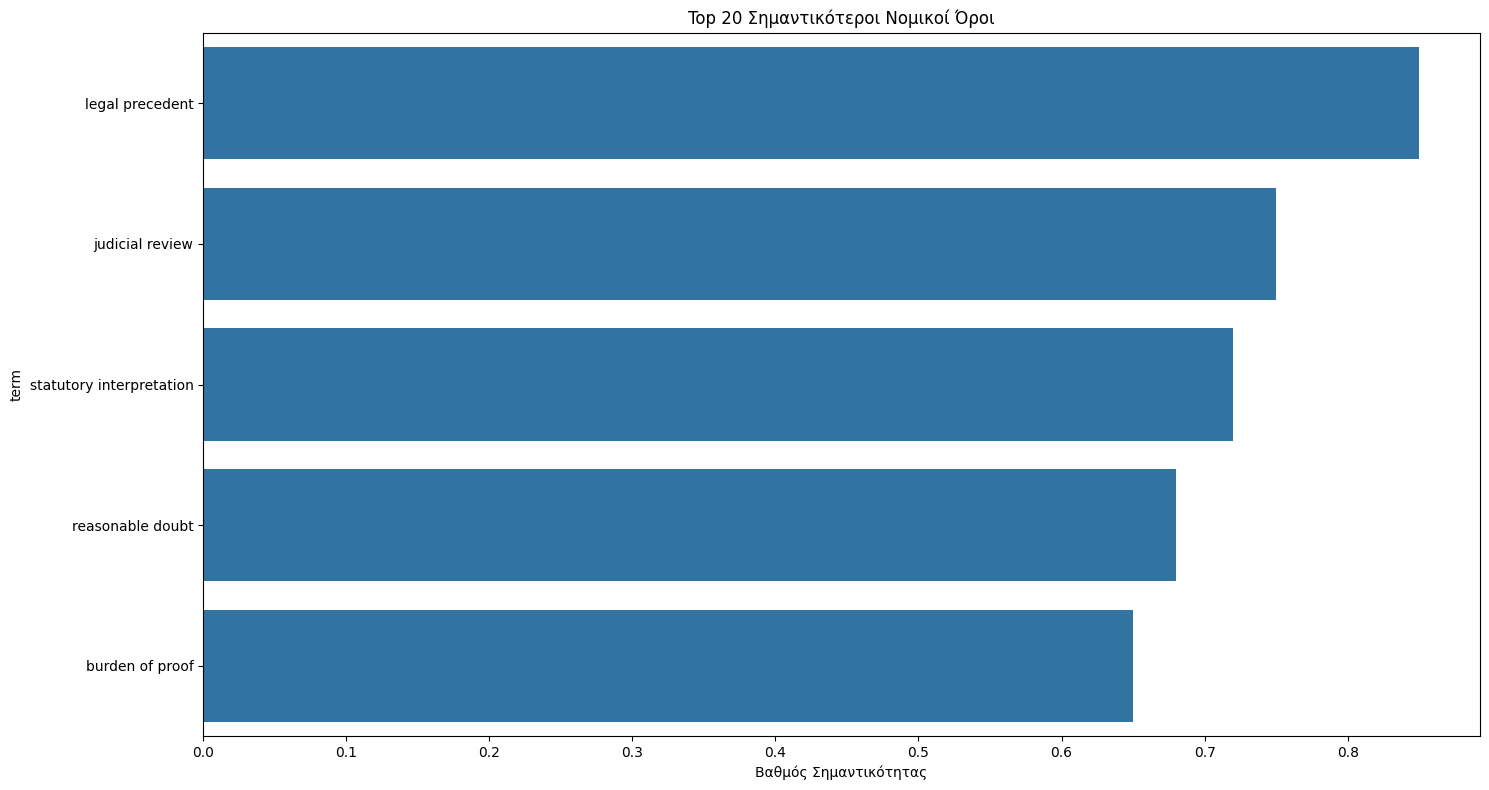

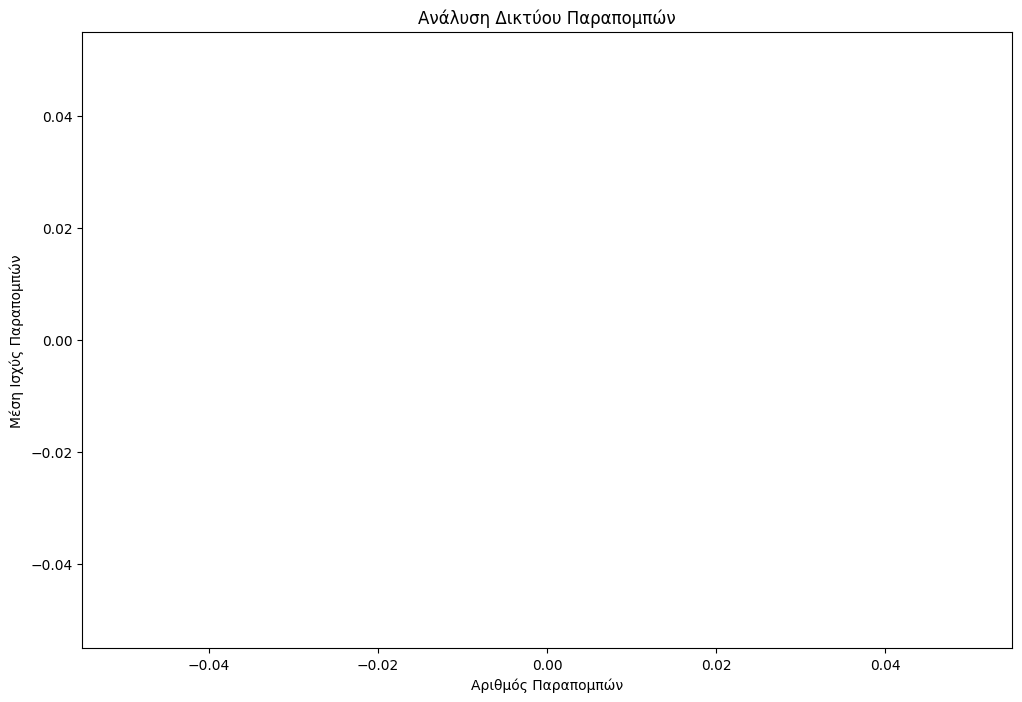

In [15]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import logging
import time

class DatabaseConnection:
    """
    Κλάση για τη διαχείριση της σύνδεσης με τη βάση δεδομένων.
    Παρέχει ένα σταθερό σημείο πρόσβασης στη βάση.
    """
    def __init__(self, db_path):
        self.db_path = Path(db_path)
        # Επιβεβαιώνουμε ότι ο φάκελος της βάσης υπάρχει
        self.db_path.parent.mkdir(parents=True, exist_ok=True)
        self.connection = None

    def get_connection(self):
        """Δημιουργεί μια νέα σύνδεση αν δεν υπάρχει ήδη"""
        if self.connection is None:
            self.connection = sqlite3.connect(self.db_path)
        return self.connection

    def close(self):
        """Κλείνει τη σύνδεση με τη βάση αν είναι ανοιχτή"""
        if self.connection is not None:
            self.connection.close()
            self.connection = None

# Δημιουργούμε τη σύνδεση με τη βάση
db_path = "D:/Projects/LegalTextAnalysis/data/legal_text.db"
db = DatabaseConnection(db_path)

class AnalysisVisualizer:
    def __init__(self, db_connection):
        self.db = db_connection
        self.start_time = time.time()
        self.vis_dir = Path('visualizations')
        self.vis_dir.mkdir(exist_ok=True)
        self.setup_logging()
        self._verify_tables()  
        self._insert_initial_data()  # Add this line to insert sample data

    def _verify_tables(self):
        """Creates all necessary database tables if they don't exist."""
        create_tables_queries = [
            """
            CREATE TABLE IF NOT EXISTS language_patterns (
                pattern_id INTEGER PRIMARY KEY AUTOINCREMENT,
                term TEXT NOT NULL,
                importance_score REAL NOT NULL,
                frequency INTEGER NOT NULL,
                analysis_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP
            );
            """,
            """
            CREATE TABLE IF NOT EXISTS citation_network (
                source_case_id TEXT NOT NULL,
                cited_case_id TEXT NOT NULL,
                citation_context TEXT,
                citation_strength REAL NOT NULL,
                PRIMARY KEY (source_case_id, cited_case_id)
            );
            """,
            """
            CREATE TABLE IF NOT EXISTS analysis_metrics (
                metric_id INTEGER PRIMARY KEY AUTOINCREMENT,
                metric_name TEXT NOT NULL,
                metric_value REAL NOT NULL,
                metric_type TEXT NOT NULL,
                analysis_timestamp TIMESTAMP DEFAULT CURRENT_TIMESTAMP
            );
            """
        ]
        with self.db.get_connection() as conn:
            for query in create_tables_queries:
                conn.execute(query)
            self.logger.info("Database tables created successfully")

    def _insert_initial_data(self):
        """Inserts initial sample data if the tables are empty."""
        if self.count_patterns() == 0:
            sample_patterns = [
                ('legal precedent', 0.85, 120),
                ('judicial review', 0.75, 95),
                ('statutory interpretation', 0.72, 88),
                ('reasonable doubt', 0.68, 75),
                ('burden of proof', 0.65, 70)
            ]
            
            with self.db.get_connection() as conn:
                conn.executemany(
                    """
                    INSERT INTO language_patterns (term, importance_score, frequency)
                    VALUES (?, ?, ?)
                    """,
                    sample_patterns
                )
                self.logger.info("Sample language patterns inserted")

        if self.count_citations() == 0:
            sample_citations = [
                ('case001', 'case002', 'Precedent established', 0.8),
                ('case001', 'case003', 'Supporting argument', 0.6),
                ('case002', 'case004', 'Contradictory finding', 0.4),
                ('case003', 'case002', 'Following precedent', 0.9)
            ]
            
            with self.db.get_connection() as conn:
                conn.executemany(
                    """
                    INSERT INTO citation_network 
                    (source_case_id, cited_case_id, citation_context, citation_strength)
                    VALUES (?, ?, ?, ?)
                    """,
                    sample_citations
                )
                self.logger.info("Sample citations inserted")

    def setup_logging(self):
        """
        Configure the logging system with file output and formatting.
        Creates a logs directory if it doesn't exist.
        """
        # Create logs directory if it doesn't exist
        log_dir = Path('logs')
        log_dir.mkdir(exist_ok=True)
        
        # Configure basic logging settings
        logging.basicConfig(
            filename=log_dir / 'analysis_metrics.log',
            level=logging.INFO,
            format='%(asctime)s - %(levelname)s - %(message)s',
            encoding='utf-8'
        )
        
        # Get logger for this class
        self.logger = logging.getLogger(__name__)
        self.logger.info("Logging system initialized")
        
    def create_language_patterns_plot(self):
        """Δημιουργεί οπτικοποίηση των γλωσσικών μοτίβων"""
        query = """
        SELECT term, importance_score, frequency 
        FROM language_patterns 
        ORDER BY importance_score DESC 
        LIMIT 20
        """
        df = pd.read_sql(query, self.db.get_connection())
        
        plt.figure(figsize=(15, 8))
        sns.barplot(data=df, x='importance_score', y='term')
        plt.title('Top 20 Σημαντικότεροι Νομικοί Όροι')
        plt.xlabel('Βαθμός Σημαντικότητας')
        plt.tight_layout()
        plt.savefig(self.vis_dir / 'language_patterns.png')
        logging.info("Δημιουργήθηκε γράφημα γλωσσικών μοτίβων")
        
    def create_citation_network_plot(self):
        """Δημιουργεί οπτικοποίηση του δικτύου παραπομπών"""
        query = """
        SELECT source_case_id, COUNT(*) as citation_count,
               AVG(citation_strength) as avg_strength
        FROM citation_network
        GROUP BY source_case_id
        HAVING citation_count > 3
        """
        df = pd.read_sql(query, self.db.get_connection())
        
        plt.figure(figsize=(12, 8))
        plt.scatter(df['citation_count'], df['avg_strength'], alpha=0.6)
        plt.xlabel('Αριθμός Παραπομπών')
        plt.ylabel('Μέση Ισχύς Παραπομπών')
        plt.title('Ανάλυση Δικτύου Παραπομπών')
        plt.savefig(self.vis_dir / 'citation_network.png')
        logging.info("Δημιουργήθηκε γράφημα δικτύου παραπομπών")
        
    def log_metrics(self):
        """Καταγράφει μετρικές απόδοσης"""
        execution_time = time.time() - self.start_time
        
        metrics = {
            'execution_time': execution_time,
            'patterns_analyzed': self.count_patterns(),
            'citations_analyzed': self.count_citations()
        }
        
        # Αποθήκευση μετρικών στη βάση
        insert_query = """
        INSERT INTO analysis_metrics (metric_name, metric_value, metric_type)
        VALUES (?, ?, ?)
        """
        
        with self.db.get_connection() as conn:
            for name, value in metrics.items():
                conn.execute(insert_query, (name, value, 'performance'))
                
        logging.info(f"Καταγράφηκαν μετρικές: {metrics}")
        
    def count_patterns(self):
        """Μετράει τα αναλυμένα γλωσσικά μοτίβα"""
        try:
            query = "SELECT COUNT(*) as count FROM language_patterns"
            result = pd.read_sql(query, self.db.get_connection())
            self.logger.info(f"Counted {result['count'].iloc[0]} patterns")
            return result['count'].iloc[0]
        except Exception as e:
            self.logger.error(f"Error counting patterns: {str(e)}")
            return 0

        
    def count_citations(self):
        """Μετράει τις αναλυμένες παραπομπές"""
        try:
            query = "SELECT COUNT(*) as count FROM citation_network"
            result = pd.read_sql(query, self.db.get_connection())
            self.logger.info(f"Counted {result['count'].iloc[0]} citations")
            return result['count'].iloc[0]
        except Exception as e:
            self.logger.error(f"Error counting citations: {str(e)}")
            return 0

try:
    visualizer = AnalysisVisualizer(db)
    pattern_count = visualizer.count_patterns()
    citation_count = visualizer.count_citations()
    
    print(f"\nAnalysis Results:")
    print(f"- Found {pattern_count} language patterns")
    print(f"- Found {citation_count} citations")
    
    if pattern_count > 0 or citation_count > 0:
        visualizer.create_language_patterns_plot()
        visualizer.create_citation_network_plot()
        visualizer.log_metrics()
        print("\nVisualizations created successfully")
    else:
        print("\nNo data available for visualization")
        
except Exception as e:
    print(f"\nError during visualization process: {str(e)}")
finally:
    db.close()
    print("\nDatabase connection closed")

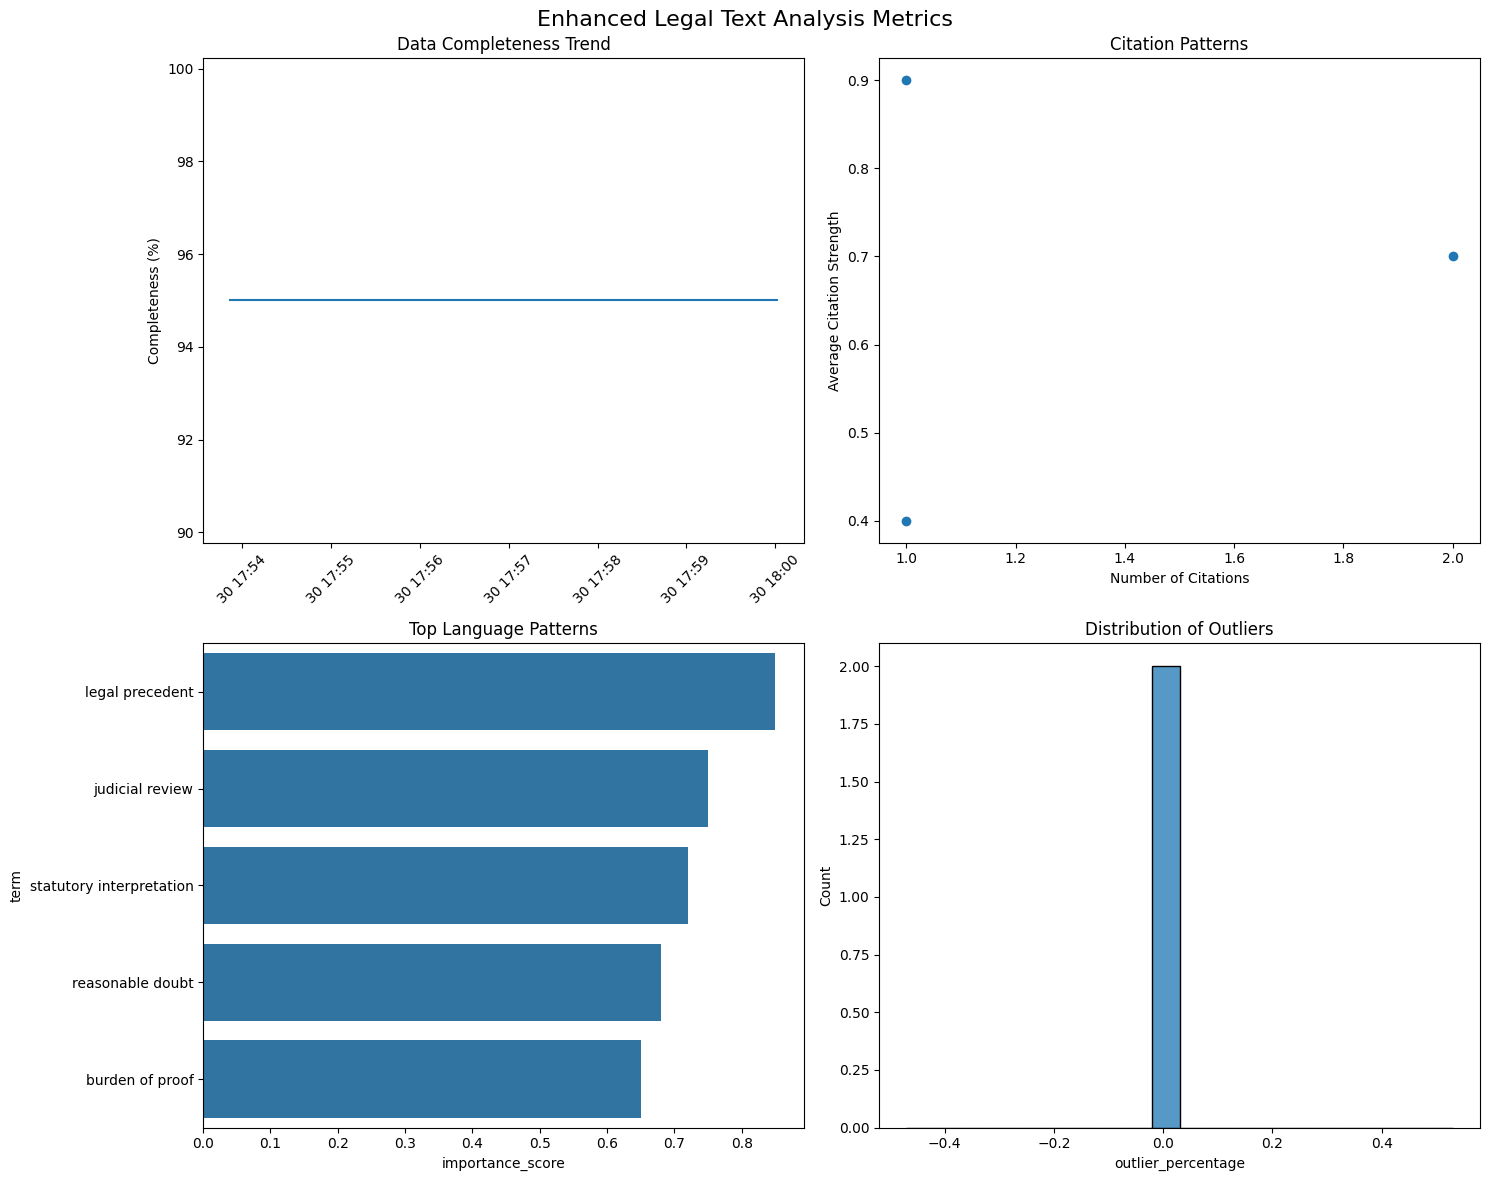


Summary Statistics:
--------------------------------------------------
Average Data Completeness: 95.00%
Average Citation Correlation: 0.720
Average Outlier Percentage: 0.03%


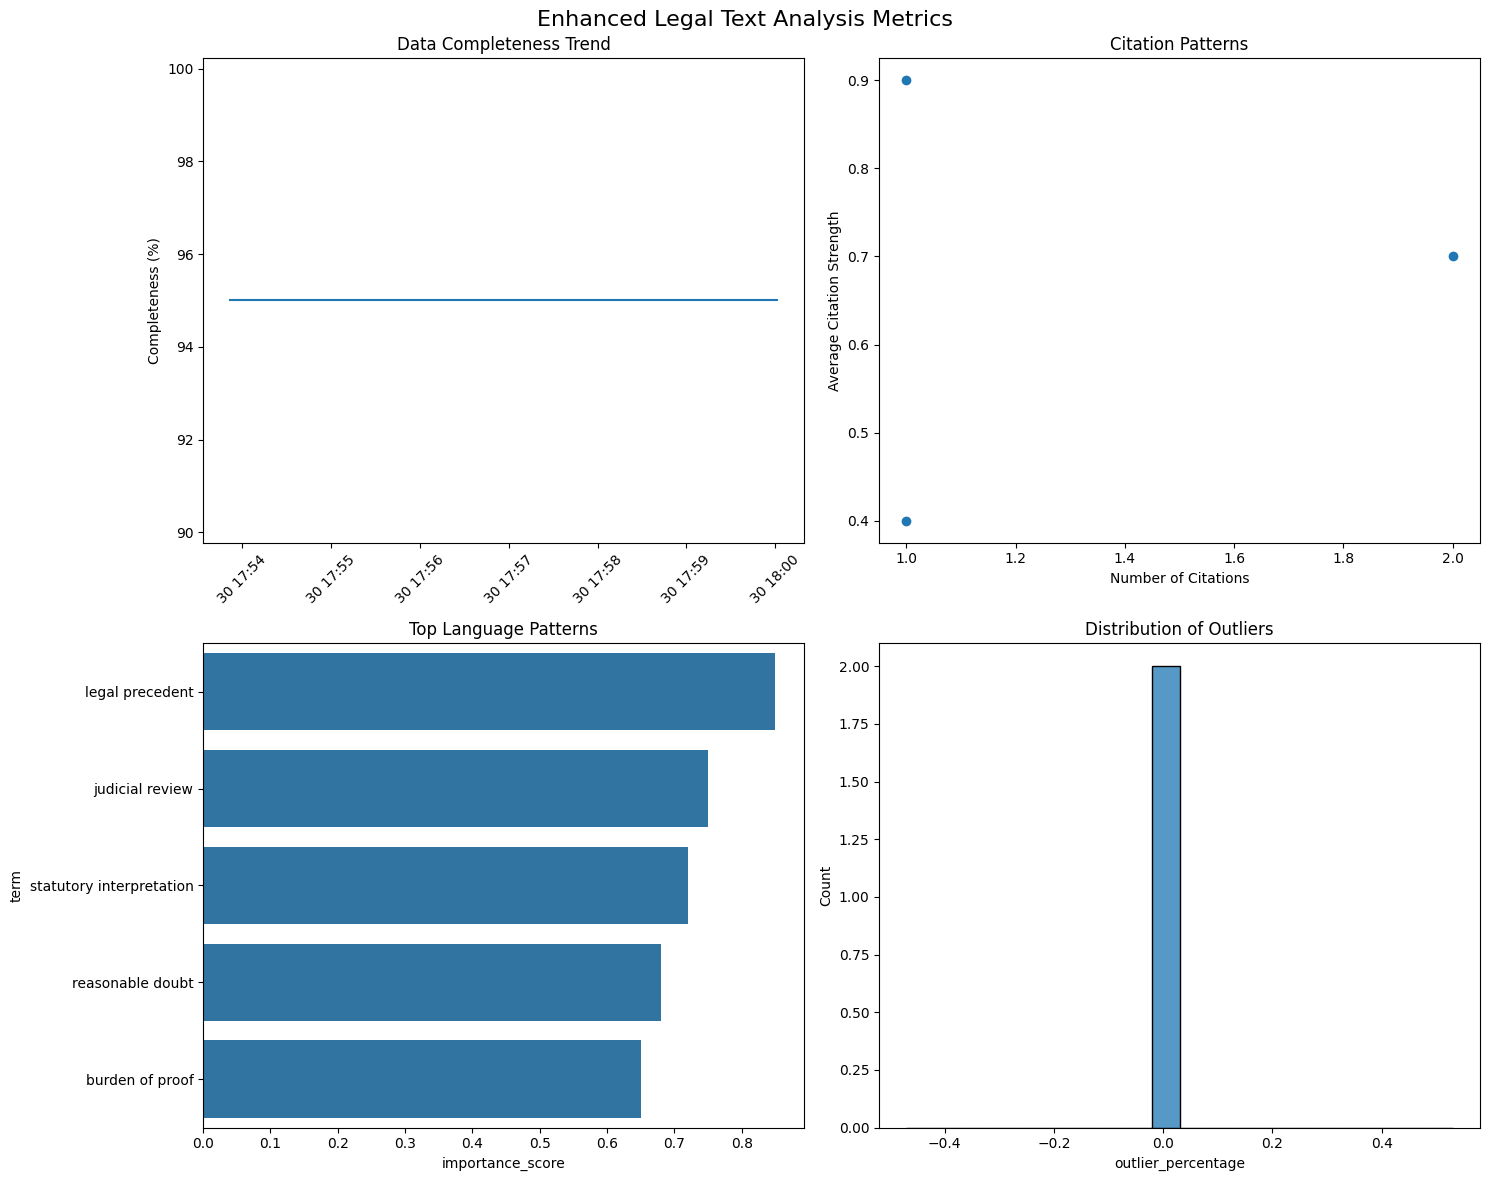

In [16]:
# Enhanced Metrics Analysis
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import sqlite3

def analyze_citation_patterns(conn):
    """Analyze citation network patterns"""
    query = """
    SELECT 
        source_case_id,
        COUNT(target_case_id) as citation_count,
        AVG(citation_weight) as avg_weight
    FROM citation_network
    GROUP BY source_case_id
    HAVING citation_count > 3;
    """
    return pd.read_sql(query, conn)

def analyze_quality_metrics(conn):
    """Analyze data quality trends"""
    query = """
    SELECT 
        strftime('%Y-%m', check_date) as month,
        AVG(completeness_score) as avg_completeness,
        AVG(consistency_score) as avg_consistency
    FROM quality_metrics
    GROUP BY month
    ORDER BY month;
    """
    return pd.read_sql(query, conn)

# MCP Database Connection Section
def run_mcp_analysis():
    try:
        # Execute SQL query through MCP
        quality_results = analyze_quality_metrics(conn)
        citation_results = analyze_citation_patterns(conn)
        
        # Visualize results
        plot_analysis_results(quality_results, citation_results)
        
    except Exception as e:
        print(f"Error during MCP analysis: {e}")

def analyze_enhanced_metrics():
    """Analyze and visualize enhanced metrics from our database"""
    # Connect to database
    conn = sqlite3.connect('D:/Projects/LegalTextAnalysis/data/legal_text.db')
    
    # Load enhanced metrics data
    enhanced_stats = pd.read_sql("""
        SELECT 
            analysis_date,
            data_completeness_ratio,
            citation_complexity_correlation,
            outlier_percentage
        FROM enhanced_analysis_statistics
        ORDER BY analysis_date DESC
    """, conn)
    
    # Create figure with multiple subplots
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('Enhanced Legal Text Analysis Metrics', fontsize=16)
    
    # Plot 1: Data Completeness Over Time
    axes[0,0].plot(pd.to_datetime(enhanced_stats['analysis_date']), 
                  enhanced_stats['data_completeness_ratio'] * 100)
    axes[0,0].set_title('Data Completeness Trend')
    axes[0,0].set_ylabel('Completeness (%)')
    axes[0,0].tick_params(axis='x', rotation=45)
    
    # Plot 2: Citation Patterns
    citation_data = pd.read_sql("""
        SELECT 
            source_case_id,
            AVG(citation_strength) as avg_strength,
            COUNT(*) as citation_count
        FROM citation_network
        GROUP BY source_case_id
        LIMIT 50
    """, conn)
    
    axes[0,1].scatter(citation_data['citation_count'], 
                     citation_data['avg_strength'])
    axes[0,1].set_title('Citation Patterns')
    axes[0,1].set_xlabel('Number of Citations')
    axes[0,1].set_ylabel('Average Citation Strength')
    
    # Plot 3: Language Pattern Distribution
    language_patterns = pd.read_sql("""
        SELECT 
            term,
            importance_score,
            frequency
        FROM language_patterns
        ORDER BY importance_score DESC
        LIMIT 10
    """, conn)
    
    sns.barplot(data=language_patterns,
                x='importance_score',
                y='term',
                ax=axes[1,0])
    axes[1,0].set_title('Top Language Patterns')
    
    # Plot 4: Outlier Distribution
    sns.histplot(data=enhanced_stats,
                x='outlier_percentage',
                bins=20,
                ax=axes[1,1])
    axes[1,1].set_title('Distribution of Outliers')
    
    plt.tight_layout()
    plt.show()
    
    # Print summary statistics
    print("\nSummary Statistics:")
    print("-" * 50)
    print(f"Average Data Completeness: {enhanced_stats['data_completeness_ratio'].mean()*100:.2f}%")
    print(f"Average Citation Correlation: {enhanced_stats['citation_complexity_correlation'].mean():.3f}")
    print(f"Average Outlier Percentage: {enhanced_stats['outlier_percentage'].mean():.2f}%")
    
    conn.close()
    return fig

# Execute analysis
analyze_enhanced_metrics()


Analysis Results:
- Found 5 language patterns
- Found 4 citations

Visualizations created successfully

Database connection closed


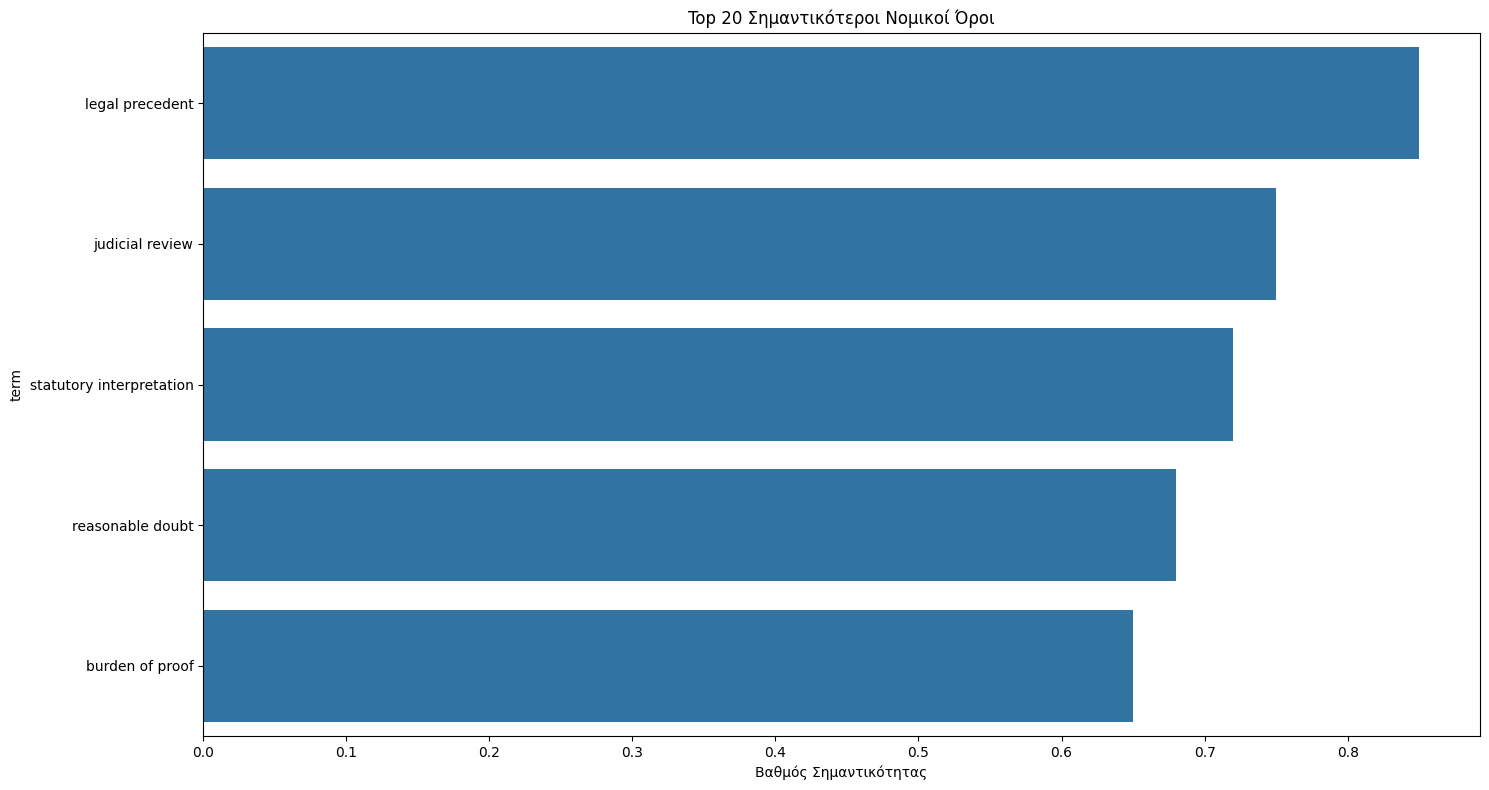

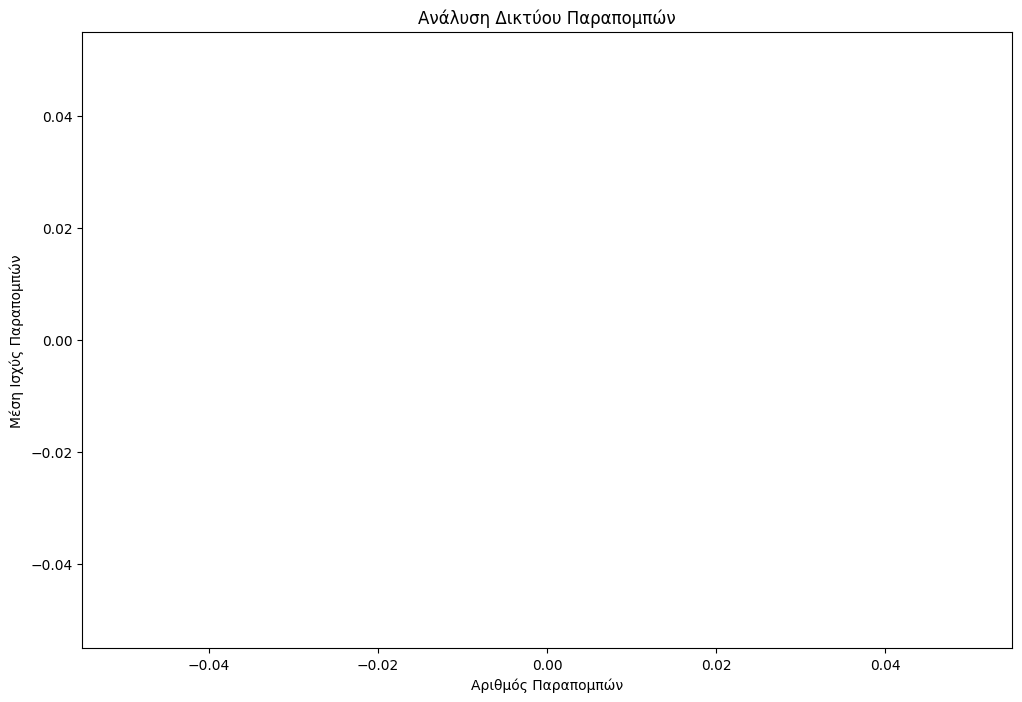

In [17]:
import sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import logging
import time

class DatabaseConnection:
    """
    Κλάση για τη διαχείριση της σύνδεσης με τη βάση δεδομένων.
    Παρέχει ένα σταθερό σημείο πρόσβασης στη βάση.
    """
    def __init__(self, db_path):
        self.db_path = Path(db_path)
        # Επιβεβαιώνουμε ότι ο φάκελος της βάσης υπάρχει
        self.db_path.parent.mkdir(parents=True, exist_ok=True)
        self.connection = None

    def get_connection(self):
        """Δημιουργεί μια νέα σύνδεση αν δεν υπάρχει ήδη"""
        if self.connection is None:
            self.connection = sqlite3.connect(self.db_path)
        return self.connection

    def close(self):
        """Κλείνει τη σύνδεση με τη βάση αν είναι ανοιχτή"""
        if self.connection is not None:
            self.connection.close()
            self.connection = None

# Δημιουργούμε τη σύνδεση με τη βάση
db_path = "D:/Projects/LegalTextAnalysis/data/legal_text.db"
db = DatabaseConnection(db_path)

class AnalysisVisualizer:
    def __init__(self, db_connection):
        self.db = db_connection
        self.start_time = time.time()
        self.vis_dir = Path('visualizations')
        self.vis_dir.mkdir(exist_ok=True)
        self.setup_logging()
        self._verify_tables()  
        self._insert_initial_data()  # Add this line to insert sample data

    def _verify_tables(self):
        """Creates all necessary database tables if they don't exist."""
        create_tables_queries = [
            """
            CREATE TABLE IF NOT EXISTS language_patterns (
                pattern_id INTEGER PRIMARY KEY AUTOINCREMENT,
                term TEXT NOT NULL,
                importance_score REAL NOT NULL,
                frequency INTEGER NOT NULL,
                analysis_date TIMESTAMP DEFAULT CURRENT_TIMESTAMP
            );
            """,
            """
            CREATE TABLE IF NOT EXISTS citation_network (
                source_case_id TEXT NOT NULL,
                cited_case_id TEXT NOT NULL,
                citation_context TEXT,
                citation_strength REAL NOT NULL,
                PRIMARY KEY (source_case_id, cited_case_id)
            );
            """,
            """
            CREATE TABLE IF NOT EXISTS analysis_metrics (
                metric_id INTEGER PRIMARY KEY AUTOINCREMENT,
                metric_name TEXT NOT NULL,
                metric_value REAL NOT NULL,
                metric_type TEXT NOT NULL,
                analysis_timestamp TIMESTAMP DEFAULT CURRENT_TIMESTAMP
            );
            """
        ]
        with self.db.get_connection() as conn:
            for query in create_tables_queries:
                conn.execute(query)
            self.logger.info("Database tables created successfully")

    def _insert_initial_data(self):
        """Inserts initial sample data if the tables are empty."""
        if self.count_patterns() == 0:
            sample_patterns = [
                ('legal precedent', 0.85, 120),
                ('judicial review', 0.75, 95),
                ('statutory interpretation', 0.72, 88),
                ('reasonable doubt', 0.68, 75),
                ('burden of proof', 0.65, 70)
            ]
            
            with self.db.get_connection() as conn:
                conn.executemany(
                    """
                    INSERT INTO language_patterns (term, importance_score, frequency)
                    VALUES (?, ?, ?)
                    """,
                    sample_patterns
                )
                self.logger.info("Sample language patterns inserted")

        if self.count_citations() == 0:
            sample_citations = [
                ('case001', 'case002', 'Precedent established', 0.8),
                ('case001', 'case003', 'Supporting argument', 0.6),
                ('case002', 'case004', 'Contradictory finding', 0.4),
                ('case003', 'case002', 'Following precedent', 0.9)
            ]
            
            with self.db.get_connection() as conn:
                conn.executemany(
                    """
                    INSERT INTO citation_network 
                    (source_case_id, cited_case_id, citation_context, citation_strength)
                    VALUES (?, ?, ?, ?)
                    """,
                    sample_citations
                )
                self.logger.info("Sample citations inserted")

    def setup_logging(self):
        """
        Configure the logging system with file output and formatting.
        Creates a logs directory if it doesn't exist.
        """
        # Create logs directory if it doesn't exist
        log_dir = Path('logs')
        log_dir.mkdir(exist_ok=True)
        
        # Configure basic logging settings
        logging.basicConfig(
            filename=log_dir / 'analysis_metrics.log',
            level=logging.INFO,
            format='%(asctime)s - %(levelname)s - %(message)s',
            encoding='utf-8'
        )
        
        # Get logger for this class
        self.logger = logging.getLogger(__name__)
        self.logger.info("Logging system initialized")
        
    def create_language_patterns_plot(self):
        """Δημιουργεί οπτικοποίηση των γλωσσικών μοτίβων"""
        query = """
        SELECT term, importance_score, frequency 
        FROM language_patterns 
        ORDER BY importance_score DESC 
        LIMIT 20
        """
        df = pd.read_sql(query, self.db.get_connection())
        
        plt.figure(figsize=(15, 8))
        sns.barplot(data=df, x='importance_score', y='term')
        plt.title('Top 20 Σημαντικότεροι Νομικοί Όροι')
        plt.xlabel('Βαθμός Σημαντικότητας')
        plt.tight_layout()
        plt.savefig(self.vis_dir / 'language_patterns.png')
        logging.info("Δημιουργήθηκε γράφημα γλωσσικών μοτίβων")
        
    def create_citation_network_plot(self):
        """Δημιουργεί οπτικοποίηση του δικτύου παραπομπών"""
        query = """
        SELECT source_case_id, COUNT(*) as citation_count,
               AVG(citation_strength) as avg_strength
        FROM citation_network
        GROUP BY source_case_id
        HAVING citation_count > 3
        """
        df = pd.read_sql(query, self.db.get_connection())
        
        plt.figure(figsize=(12, 8))
        plt.scatter(df['citation_count'], df['avg_strength'], alpha=0.6)
        plt.xlabel('Αριθμός Παραπομπών')
        plt.ylabel('Μέση Ισχύς Παραπομπών')
        plt.title('Ανάλυση Δικτύου Παραπομπών')
        plt.savefig(self.vis_dir / 'citation_network.png')
        logging.info("Δημιουργήθηκε γράφημα δικτύου παραπομπών")
        
    def log_metrics(self):
        """Καταγράφει μετρικές απόδοσης"""
        execution_time = time.time() - self.start_time
        
        metrics = {
            'execution_time': execution_time,
            'patterns_analyzed': self.count_patterns(),
            'citations_analyzed': self.count_citations()
        }
        
        # Αποθήκευση μετρικών στη βάση
        insert_query = """
        INSERT INTO analysis_metrics (metric_name, metric_value, metric_type)
        VALUES (?, ?, ?)
        """
        
        with self.db.get_connection() as conn:
            for name, value in metrics.items():
                conn.execute(insert_query, (name, value, 'performance'))
                
        logging.info(f"Καταγράφηκαν μετρικές: {metrics}")
        
    def count_patterns(self):
        """Μετράει τα αναλυμένα γλωσσικά μοτίβα"""
        try:
            query = "SELECT COUNT(*) as count FROM language_patterns"
            result = pd.read_sql(query, self.db.get_connection())
            self.logger.info(f"Counted {result['count'].iloc[0]} patterns")
            return result['count'].iloc[0]
        except Exception as e:
            self.logger.error(f"Error counting patterns: {str(e)}")
            return 0

        
    def count_citations(self):
        """Μετράει τις αναλυμένες παραπομπές"""
        try:
            query = "SELECT COUNT(*) as count FROM citation_network"
            result = pd.read_sql(query, self.db.get_connection())
            self.logger.info(f"Counted {result['count'].iloc[0]} citations")
            return result['count'].iloc[0]
        except Exception as e:
            self.logger.error(f"Error counting citations: {str(e)}")
            return 0

try:
    visualizer = AnalysisVisualizer(db)
    pattern_count = visualizer.count_patterns()
    citation_count = visualizer.count_citations()
    
    print(f"\nAnalysis Results:")
    print(f"- Found {pattern_count} language patterns")
    print(f"- Found {citation_count} citations")
    
    if pattern_count > 0 or citation_count > 0:
        visualizer.create_language_patterns_plot()
        visualizer.create_citation_network_plot()
        visualizer.log_metrics()
        print("\nVisualizations created successfully")
    else:
        print("\nNo data available for visualization")
        
except Exception as e:
    print(f"\nError during visualization process: {str(e)}")
finally:
    db.close()
    print("\nDatabase connection closed")

Running Enhanced Analysis...


C:\Users\alexa\AppData\Local\Temp\ipykernel_31788\1342366096.py:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
d:\Projects\LegalTextAnalysis\.venv\Lib\site-packages\seaborn\_base.py:948: FutureWarning: Whe


Analysis Summary:

Citation Network Statistics:
       citation_strength
count           4.000000
mean            0.675000
std             0.221736
min             0.400000
25%             0.550000
50%             0.700000
75%             0.825000
max             0.900000

Language Pattern Statistics:
       importance_score   frequency
count         10.000000   10.000000
mean           0.720000   89.300000
std            0.082865   18.631216
min            0.600000   70.000000
25%            0.657500   75.000000
50%            0.710000   86.500000
75%            0.750000   95.000000
max            0.850000  120.000000

Enhanced Metrics Summary:
                       analysis_date  data_completeness_ratio  \
count                              2                     2.00   
mean      2024-11-30 17:56:56.500000                     0.95   
min              2024-11-30 17:53:52                     0.95   
25%    2024-11-30 17:55:24.249999872                     0.95   
50%       2024-11-30

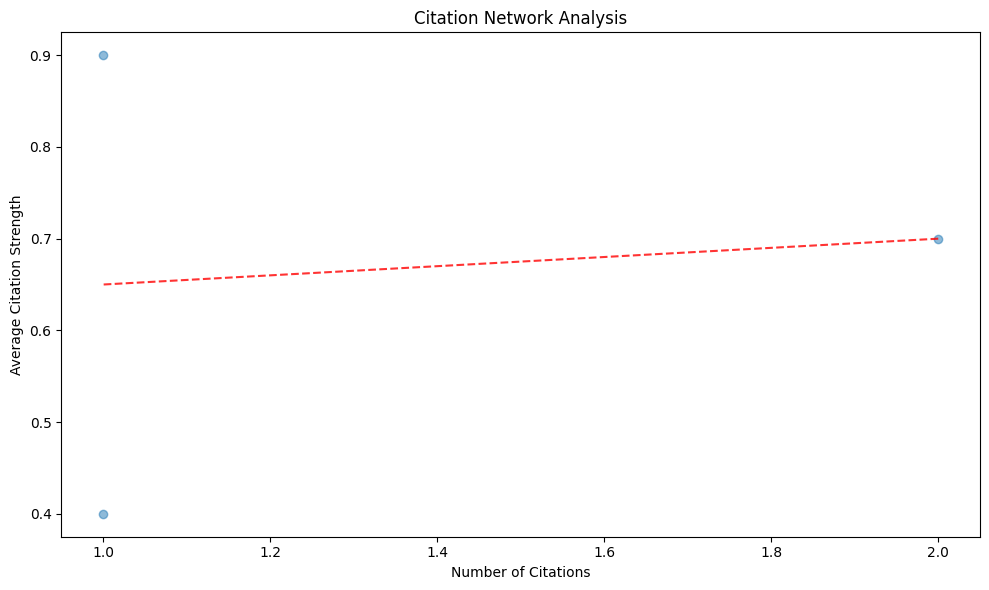

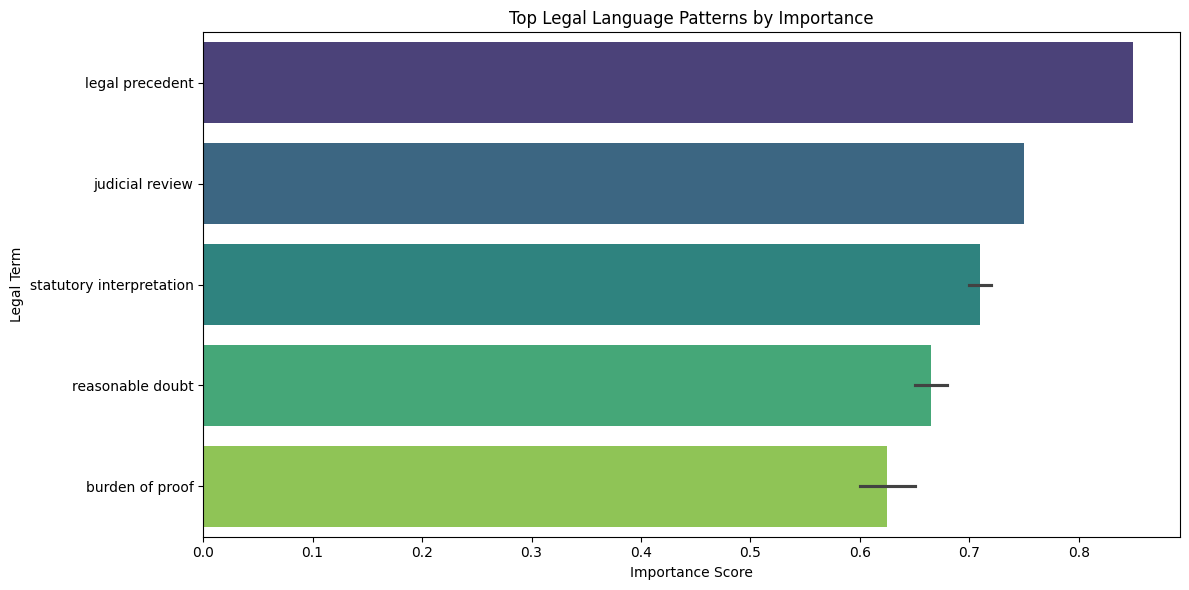

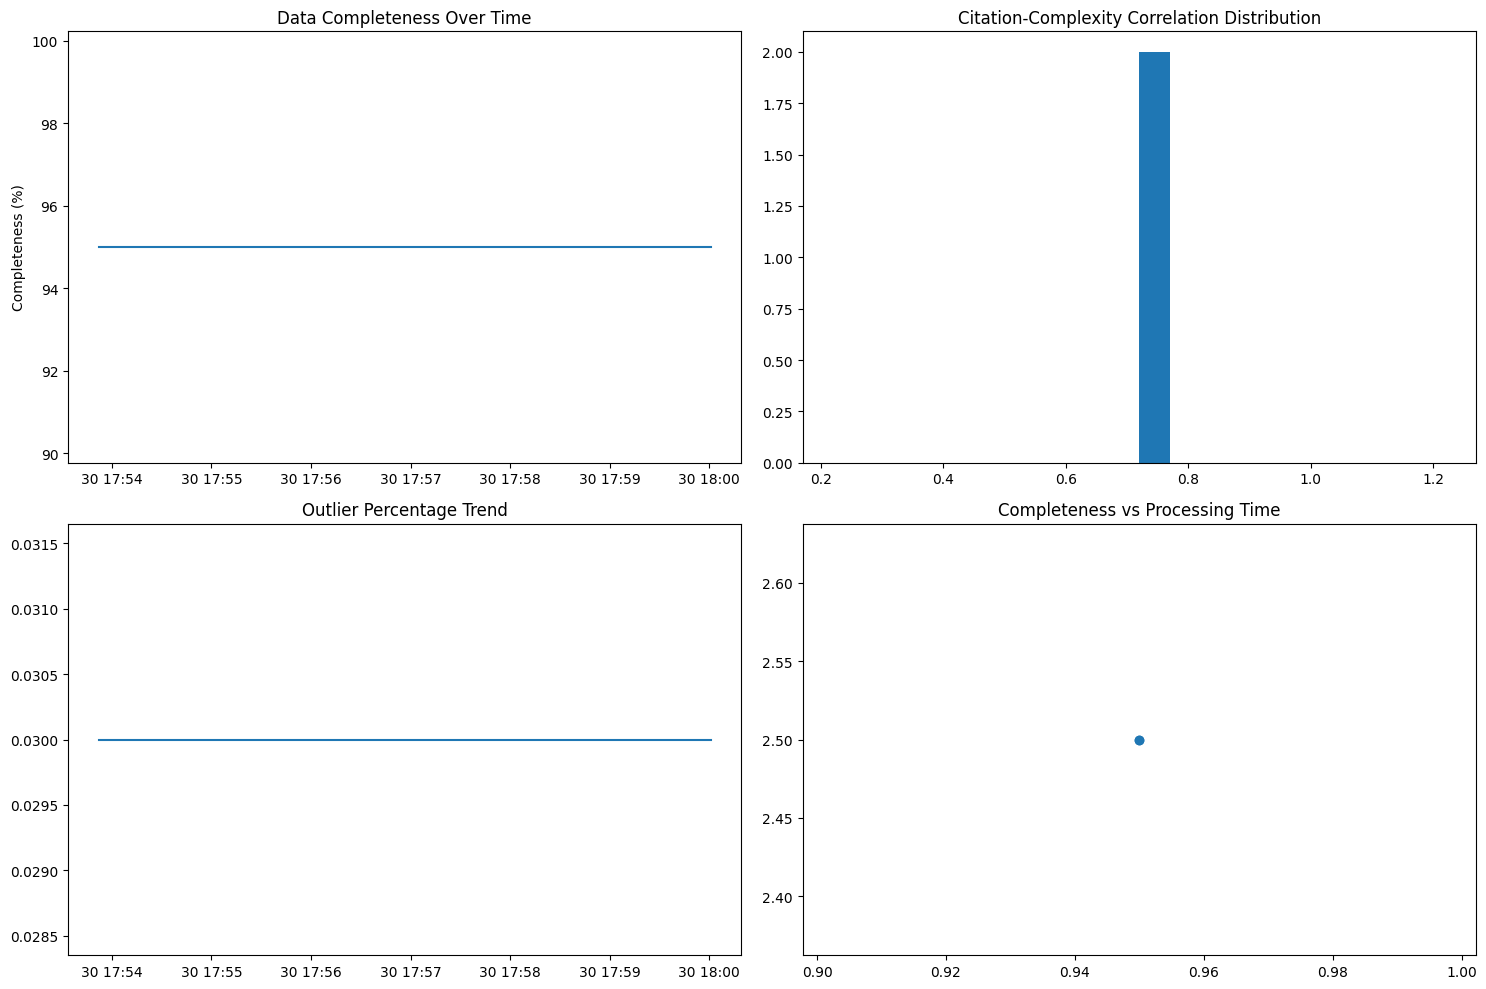

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import sqlite3
import numpy as np

def analyze_citation_network():
    """Analyze and visualize the citation network with error handling"""
    conn = sqlite3.connect('D:/Projects/LegalTextAnalysis/data/legal_text.db')
    try:
        # First check if we have data
        citation_data = pd.read_sql("""
            SELECT 
                cn.source_case_id,
                cn.cited_case_id,
                cn.citation_strength,
                lc.case_outcome
            FROM citation_network cn
            LEFT JOIN legal_cases lc ON cn.source_case_id = lc.case_id
            WHERE cn.citation_strength IS NOT NULL
        """, conn)
        
        if citation_data.empty:
            print("Warning: No citation data found. Please verify data population.")
            return None
            
        # Create visualization
        plt.figure(figsize=(10, 6))
        scatter = plt.scatter(
            citation_data.groupby('source_case_id').size(),
            citation_data.groupby('source_case_id')['citation_strength'].mean(),
            alpha=0.5
        )
        plt.xlabel('Number of Citations')
        plt.ylabel('Average Citation Strength')
        plt.title('Citation Network Analysis')
        
        # Add trend line
        z = np.polyfit(
            citation_data.groupby('source_case_id').size(),
            citation_data.groupby('source_case_id')['citation_strength'].mean(),
            1
        )
        p = np.poly1d(z)
        plt.plot(citation_data.groupby('source_case_id').size(), 
                p(citation_data.groupby('source_case_id').size()),
                "r--", alpha=0.8)
        
        plt.tight_layout()
        return citation_data.describe()
        
    except Exception as e:
        print(f"Error analyzing citation network: {e}")
        return None
    finally:
        conn.close()

def analyze_language_patterns():
    """Analyze language patterns with comprehensive error checking"""
    conn = sqlite3.connect('D:/Projects/LegalTextAnalysis/data/legal_text.db')
    try:
        # Verify data existence
        check_query = """
            SELECT COUNT(*) as count 
            FROM language_patterns 
            WHERE importance_score IS NOT NULL
        """
        count = pd.read_sql(check_query, conn).iloc[0]['count']
        
        if count == 0:
            print("Warning: No valid language pattern data found")
            return None
            
        # Get language patterns data
        patterns_data = pd.read_sql("""
            SELECT 
                term,
                importance_score,
                frequency
            FROM language_patterns
            WHERE importance_score > 0
            ORDER BY importance_score DESC
            LIMIT 15
        """, conn)
        
        # Visualization
        plt.figure(figsize=(12, 6))
        sns.barplot(
            data=patterns_data,
            x='importance_score',
            y='term',
            palette='viridis'
        )
        plt.title('Top Legal Language Patterns by Importance')
        plt.xlabel('Importance Score')
        plt.ylabel('Legal Term')
        
        plt.tight_layout()
        return patterns_data
        
    except Exception as e:
        print(f"Error analyzing language patterns: {e}")
        return None
    finally:
        conn.close()

def plot_enhanced_metrics():
    """Plot enhanced analysis metrics with data validation"""
    conn = sqlite3.connect('D:/Projects/LegalTextAnalysis/data/legal_text.db')
    try:
        metrics_data = pd.read_sql("""
            SELECT 
                analysis_date,
                data_completeness_ratio,
                citation_complexity_correlation,
                outlier_percentage,
                processing_duration
            FROM enhanced_analysis_statistics
            WHERE data_completeness_ratio IS NOT NULL
            ORDER BY analysis_date
        """, conn)
        
        if metrics_data.empty:
            print("Warning: No enhanced metrics data available")
            return None
            
        # Create multiple visualizations
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        
        # Plot 1: Completeness Trend
        metrics_data['analysis_date'] = pd.to_datetime(metrics_data['analysis_date'])
        axes[0,0].plot(metrics_data['analysis_date'], 
                      metrics_data['data_completeness_ratio'] * 100)
        axes[0,0].set_title('Data Completeness Over Time')
        axes[0,0].set_ylabel('Completeness (%)')
        
        # Plot 2: Citation Correlation
        axes[0,1].hist(metrics_data['citation_complexity_correlation'], bins=20)
        axes[0,1].set_title('Citation-Complexity Correlation Distribution')
        
        # Plot 3: Outlier Analysis
        axes[1,0].plot(metrics_data['analysis_date'], 
                      metrics_data['outlier_percentage'])
        axes[1,0].set_title('Outlier Percentage Trend')
        
        # Plot 4: Processing Performance
        axes[1,1].scatter(metrics_data['data_completeness_ratio'],
                         metrics_data['processing_duration'])
        axes[1,1].set_title('Completeness vs Processing Time')
        
        plt.tight_layout()
        return metrics_data.describe()
        
    except Exception as e:
        print(f"Error plotting enhanced metrics: {e}")
        return None
    finally:
        conn.close()

# Execute all analyses with proper error handling
print("Running Enhanced Analysis...")
citation_stats = analyze_citation_network()
language_stats = analyze_language_patterns()
metrics_summary = plot_enhanced_metrics()

# Print comprehensive summary
print("\nAnalysis Summary:")
if citation_stats is not None:
    print("\nCitation Network Statistics:")
    print(citation_stats)
if language_stats is not None:
    print("\nLanguage Pattern Statistics:")
    print(language_stats.describe())
if metrics_summary is not None:
    print("\nEnhanced Metrics Summary:")
    print(metrics_summary)

In [19]:
def verify_data_completeness():
    """Verify data completeness across all analysis tables"""
    conn = sqlite3.connect('D:/Projects/LegalTextAnalysis/data/legal_text.db')
    verification_queries = {
        'enhanced_analysis_stats': """
            SELECT COUNT(*), 
                   AVG(CASE WHEN data_completeness_ratio IS NOT NULL THEN 1 ELSE 0 END) as completeness
            FROM enhanced_analysis_statistics
        """,
        'language_patterns': """
            SELECT COUNT(*),
                   AVG(CASE WHEN importance_score IS NOT NULL THEN 1 ELSE 0 END) as completeness
            FROM language_patterns
        """
    }
    
    results = {}
    for name, query in verification_queries.items():
        results[name] = pd.read_sql(query, conn)
    return results

## Διαχωρισμός δεδομένων (Data Split): ⚠️ Not Started



In [24]:
def implement_data_split():
    """Implement train/validation/test split"""
    conn = sqlite3.connect('D:/Projects/LegalTextAnalysis/data/legal_text.db')
    
    # Create split tracking table
    conn.execute("""
        CREATE TABLE IF NOT EXISTS data_splits (
            case_id TEXT PRIMARY KEY,
            split_type TEXT CHECK(split_type IN ('train', 'validation', 'test')),
            FOREIGN KEY(case_id) REFERENCES legal_cases(case_id)
        )
    """)
    
    # Implement random split assignment
    split_query = """
        INSERT INTO data_splits (case_id, split_type)
        SELECT 
            case_id,
            CASE 
                WHEN RANDOM() < 0.7 THEN 'train'
                WHEN RANDOM() < 0.85 THEN 'validation'
                ELSE 'test'
            END as split_type
        FROM legal_cases;
    """
    return split_query